/var/folders/p_/flb84jgs2_jbb5_gnn1645jw0000gn/T/ipykernel_57096/3494481602.py:80: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors  = get_cmap('viridis_r')(p)    # reversed viridis


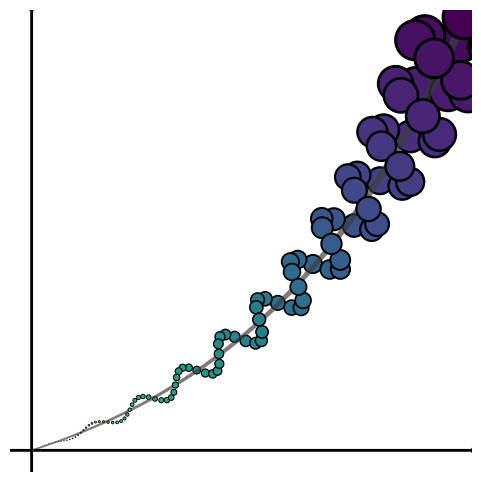

In [10]:
#  Natural-exponential backbone (y = e^{kx} − 1) with tapered stroke
#  Helical bead path (sine offset along normal)
#  Beads coloured by reversed Viridis
#  Depth layering:
#        1. back-half beads   (depth < 0)
#        2. backbone curve
#        3. front-half beads  (depth > 0)
#     so the strand appears to wind in front of / behind the exponential.

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.collections import LineCollection
from matplotlib.cm import get_cmap
from scipy.integrate import cumulative_trapezoid
from scipy.interpolate import interp1d

# knobs
x_max, n_samples = 6.0, 4000
n_turns, A_max   = 12, 0.55
n_beads          = 120
spacing_exp      = 1.6
r_min, r_max     = 1e-4, 0.30
growth_pow       = 1.4
pad              = 0.4
lw_back_min, lw_back_max = 1.0, 6.0   # backbone stroke
lw_edge_min, lw_edge_max = 0.3, 2.2   # bead edge stroke

# backbone: scaled exponential that ends at (x_max, x_max)
k        = np.log1p(x_max) / x_max
backbone = lambda x: np.exp(k*x) - 1

t               = np.linspace(0, x_max, n_samples)
xB, yB          = t, backbone(t)
dy_dx           = k*np.exp(k*t)

# arc-length for tapered line width
speedB          = np.hypot(np.ones_like(t), dy_dx)
sB              = np.concatenate([[0], cumulative_trapezoid(speedB, t)])
LB              = sB[-1]
segB            = np.stack([np.column_stack([xB[:-1], yB[:-1]]),
                            np.column_stack([xB[1:],  yB[1: ]])], axis=1)
w_back          = lw_back_min + (lw_back_max-lw_back_min)*(sB[:-1]/LB)
backbone_lc     = LineCollection(segB, linewidths=w_back,
                                 colors='0.25', zorder=2)

# ── helix path (for bead positions only) ─────────────────────
dx, dy          = np.ones_like(t), dy_dx
speed           = np.hypot(dx, dy)
s_full          = np.concatenate([[0], cumulative_trapezoid(speed, t)])
L               = s_full[-1]

Tx, Ty          = dx/speed, dy/speed
Nx, Ny          = -Ty, Tx
amp             = A_max * (s_full/L)
phi             = 2*np.pi*n_turns * s_full/L
X               = xB + amp*np.sin(phi)*Nx
Y               = yB + amp*np.sin(phi)*Ny

ix, iy          = interp1d(s_full, X), interp1d(s_full, Y)

# bead centres, sizes, colours, edge widths
p       = np.linspace(0, 1, n_beads)
s_beads = L * p**spacing_exp
Xi, Yi  = ix(s_beads), iy(s_beads)

radii   = r_min + (r_max - r_min)*(s_beads/L)**growth_pow
lw_edge = lw_edge_min + (lw_edge_max-lw_edge_min)*(s_beads/L)

# depth = +front / −back
amp_i   = A_max * (s_beads/L)
phi_i   = 2*np.pi*n_turns * s_beads/L
depth   = amp_i * np.cos(phi_i)

back_ids  = np.where(depth < 0)[0][np.argsort(depth[depth < 0])]        # far→near
front_ids = np.where(depth >= 0)[0][np.argsort(depth[depth >= 0])]      # far→near

colors  = get_cmap('viridis_r')(p)    # reversed viridis

# square plot with layered drawing
side = x_max + pad
fig, ax = plt.subplots(figsize=(6, 6))

# layer 1: back-half beads
for i in back_ids:
    ax.add_patch(Circle((Xi[i], Yi[i]), radii[i],
                        fc=colors[i], ec='black', lw=lw_edge[i], zorder=1))

# layer 2: exponential backbone
ax.add_collection(backbone_lc)

# layer 3: front-half beads
for i in front_ids:
    ax.add_patch(Circle((Xi[i], Yi[i]), radii[i],
                        fc=colors[i], ec='black', lw=lw_edge[i], zorder=3))

# axes
ax.arrow(-0.3, 0, side, 0, width=.02, color='black')
ax.arrow(0, -0.3, 0, side, width=.02, color='black')
ax.set_xlim(-0.3, side-0.3); ax.set_ylim(-0.3, side-0.3)
ax.set_aspect('equal'); ax.axis('off')

fig.savefig('chromatin_helix_depthwrap.svg', format='svg', bbox_inches='tight')
fig.savefig('chromatin_helix_depthwrap.png', dpi=300, bbox_inches='tight')
plt.show()


/var/folders/p_/flb84jgs2_jbb5_gnn1645jw0000gn/T/ipykernel_57096/2159861859.py:76: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = get_cmap('viridis')(p)


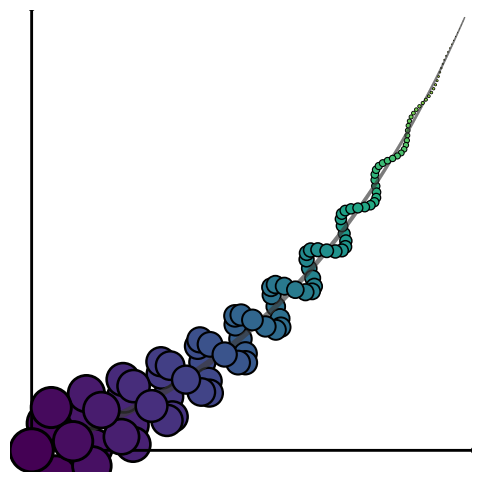

In [2]:
#  Same inverse helix — only one tweak:
#      spacing_exp  0.85  →  0.80
#  That leaves the big beads at the origin almost touching,
#  while tightening the gaps between the tiny beads near
#  (x_max , x_max).

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.collections import LineCollection
from matplotlib.cm import get_cmap
from scipy.integrate import cumulative_trapezoid
from scipy.interpolate import interp1d

# parameters
x_max, n_samples = 6.0, 4000
n_turns          = 12
A_max            = 0.55
decay_pow        = 1.3
n_beads          = 120
spacing_exp      = 0.80
r_min, r_max     = 1e-3, 0.30
growth_pow       = 1.4
pad              = 0.4
lw_back_max, lw_back_min = 6.0, 1.0
lw_edge_max, lw_edge_min = 2.2, 0.3

# backbone (scaled exponential)
k        = np.log1p(x_max) / x_max
backbone = lambda x: np.exp(k*x) - 1
t   = np.linspace(0, x_max, n_samples)
xB, yB = t, backbone(t)
dy_dx  = k*np.exp(k*t)

speedB = np.hypot(np.ones_like(t), dy_dx)
sB     = np.concatenate([[0], cumulative_trapezoid(speedB, t)])
LB     = sB[-1]

segments = np.stack([np.column_stack([xB[:-1], yB[:-1]]),
                     np.column_stack([xB[1:],  yB[1: ]])], axis=1)
w_back   = lw_back_max - (lw_back_max-lw_back_min)*(sB[:-1]/LB)
backbone_lc = LineCollection(segments, linewidths=w_back, colors='0.25', zorder=2)

# helix path (for bead placement)
dx, dy  = np.ones_like(t), dy_dx
speed   = np.hypot(dx, dy)
s_full  = np.concatenate([[0], cumulative_trapezoid(speed, t)])
L       = s_full[-1]

amp   = A_max * (1 - s_full/L)**decay_pow
phi   = 2*np.pi*n_turns * (1 - s_full/L)**decay_pow
Tx, Ty = dx/speed, dy/speed
Nx, Ny = -Ty, Tx
X      = xB + amp*np.sin(phi)*Nx
Y      = yB + amp*np.sin(phi)*Ny

ix, iy = interp1d(s_full, X), interp1d(s_full, Y)

# bead properties
p        = np.linspace(0, 1, n_beads)
s_beads  = L * p**spacing_exp
Xi, Yi   = ix(s_beads), iy(s_beads)

radii    = r_min + (r_max-r_min)*(1 - s_beads/L)**growth_pow
lw_edge  = lw_edge_max - (lw_edge_max-lw_edge_min)*(s_beads/L)

amp_i = A_max * (1 - s_beads/L)**decay_pow
phi_i = 2*np.pi*n_turns * (1 - s_beads/L)**decay_pow
depth = amp_i * np.cos(phi_i)

back_ids  = np.where(depth < 0)[0][np.argsort(depth[depth < 0])]
front_ids = np.where(depth >= 0)[0][np.argsort(depth[depth >= 0])]

colors = get_cmap('viridis')(p)

# plot
side = x_max + pad
fig, ax = plt.subplots(figsize=(6, 6))

for i in back_ids:
    ax.add_patch(Circle((Xi[i], Yi[i]), radii[i],
                        fc=colors[i], ec='black', lw=lw_edge[i], zorder=1))

ax.add_collection(backbone_lc)

for i in front_ids:
    ax.add_patch(Circle((Xi[i], Yi[i]), radii[i],
                        fc=colors[i], ec='black', lw=lw_edge[i], zorder=3))

ax.arrow(-0.3, 0, side, 0, width=.02, color='black')
ax.arrow(0, -0.3, 0, side, width=.02, color='black')
ax.set_xlim(-0.3, side-0.3); ax.set_ylim(-0.3, side-0.3)
ax.set_aspect('equal'); ax.axis('off')

fig.savefig('chromatin_helix_inverse_tighter_end.svg', format='svg', bbox_inches='tight')
fig.savefig('chromatin_helix_inverse_tighter_end.png', dpi=300, bbox_inches='tight')
plt.show()
